Research Question: How does the proportion of fatal motor-vehicle crashes involving alcohol consumption differ between major U.S. holidays and comparable non-holiday periods, and how has this relationship changed from 2019 to 2024?

In [ ]:
import numpy as np
import pandas as pd
import holidays
from datetime import timedelta
import matplotlib.pyplot as plt

Load and check the crash data

We combined six years of FARS crash data. Each row represents one fatal crash. We checked for duplicates using YEAR and ST_CASE together because a crash ID can appear in more than one year. The combined table had 222,695 crashes.

In [13]:
annual_crashes = []

for year in range(2019, 2025):
    filename = "accident.CSV" if year == 2019 else "accident.csv"
    file_path = f"raw/FARS{year}NationalCSV/{filename}"
    data = pd.read_csv(file_path, encoding="latin1", low_memory=False)
    data.columns = data.columns.str.replace("ï»¿", "", regex=False)
    data["YEAR"] = year
    annual_crashes.append(data)

crashes = pd.concat(annual_crashes, ignore_index=True)

print(crashes["YEAR"].value_counts().sort_index())
print("Total crashes", len(crashes))

crashes.to_csv(
    "processed/combined_accident_2019_2024.csv",
    index=False)

YEAR
2019    33487
2020    35935
2021    39785
2022    39422
2023    37769
2024    36297
Name: count, dtype: int64
Total crashes 222695


In [9]:
columns_to_keep = ["YEAR", "ST_CASE", "MONTH", "DAY", "HOUR", "DAY_WEEK", "STATE", "WEATHER"]
crash_data = crashes[columns_to_keep].copy()

print("Rows and columns", crash_data.shape)
crash_data.head()

Rows and columns (222695, 8)


,YEAR,ST_CASE,MONTH,DAY,HOUR,DAY_WEEK,STATE,WEATHER
0,2019,10001,2,7,12,5,1,1
1,2019,10002,1,23,18,4,1,2
2,2019,10003,1,22,19,3,1,10
3,2019,10004,1,22,3,3,1,1
4,2019,10005,1,18,5,6,1,5


Check for missing values

FARS uses number codes for some missing values. We changed those codes in the hour and weather columns so pandas could count them. About 0.75% of crashes had a missing hour, and 5.04% had missing weather. We kept these rows because we could still use the crash date.

In [11]:
missing = float("nan")

crash_data["HOUR"] = crash_data["HOUR"].replace(99, missing)
crash_data["WEATHER"] = crash_data["WEATHER"].replace([98, 99], missing)

print(crash_data[["HOUR", "WEATHER"]].isna().sum())
print("Total crashes", len(crash_data))

HOUR        1668
WEATHER    11234
dtype: int64
Total crashes 222695


In [12]:
#Calculating the percentage of crashes missing hour or weather
total_crashes = len(crash_data)
missing_counts = crash_data[["HOUR", "WEATHER"]].isna().sum()
missing_percentages = missing_counts / total_crashes * 100

print("Percentage of crashes with missing values")
print(missing_percentages.round(2))

Percentage of crashes with missing values
HOUR       0.75
WEATHER    5.04
dtype: float64


In [13]:
#Creating a crash date from year, month, and day
crash_data["DATE"] = pd.to_datetime(crash_data[["YEAR", "MONTH", "DAY"]])

print(crash_data[["YEAR", "MONTH", "DAY", "DATE"]].head())

   YEAR  MONTH  DAY       DATE
0  2019      2    7 2019-02-07
1  2019      1   23 2019-01-23
2  2019      1   22 2019-01-22
3  2019      1   22 2019-01-22
4  2019      1   18 2019-01-18


Create the date and find the holidays


We combined the year, month, and day into one date. Then we used the holidays package to find New Year’s Day, Memorial Day, Independence Day, Labor Day, Thanksgiving Day, and Christmas Day. We used the actual calendar dates, which gave us 36 holiday dates across six years.

In [ ]:
us_holidays = holidays.US(years=range(2019, 2025), observed=False)

holiday_names = {
    "New Year's Day",
    "Memorial Day",
    "Independence Day",
    "Labor Day",
    "Thanksgiving Day",
    "Christmas Day"
}
holiday_dates = [
    date for date, name in us_holidays.items()
    if name in holiday_names
]
is_holiday_day = crash_data["DATE"].dt.date.isin(holiday_dates)
crash_data["HOLIDAY_DAY"] = is_holiday_day.astype(int)

print("Holiday dates", len(holiday_dates))
print(crash_data["HOLIDAY_DAY"].value_counts().sort_index())

Holiday dates 36
HOLIDAY_DAY
0    218657
1      4038
Name: count, dtype: int64


Add the BAC data


We joined the BAC data to the crash data using the year and crash ID. The join found a BAC row for 222,319 crashes. The remaining 376 crashes had no coded driver, so we left them out of the BAC analysis.

FARS gives ten versions of the highest driver BAC in each crash to account for missing test results. For each version, we marked a crash as involving an impaired driver if the highest BAC was at least 0.08.

In [16]:
annual_bac = []

for year in range(2019, 2025):
    file_path = f"raw/FARS{year}NationalCSV/MIDRVACC.CSV"
    bac_year = pd.read_csv(file_path)
    bac_year["YEAR"] = year
    annual_bac.append(bac_year)

bac_data = pd.concat(annual_bac, ignore_index=True)

print("Rows and columns", bac_data.shape)
bac_data.head()

Rows and columns (222319, 12)


,ST_CASE,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,YEAR
0,10001,0,0,0,0,0,0,0,0,0,0,2019
1,10002,0,0,0,0,0,0,0,0,0,0,2019
2,10003,0,0,0,0,0,0,0,0,0,0,2019
3,10004,0,0,0,0,0,0,0,0,0,0,2019
4,10005,23,23,23,23,23,23,23,23,23,23,2019


In [17]:
crash_bac = crash_data.merge(
    bac_data,
    on=["YEAR", "ST_CASE"],
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Total crashes", len(crash_bac))
print(crash_bac["_merge"].value_counts())

Total crashes 222695
_merge
both          222319
left_only        376
right_only         0
Name: count, dtype: int64


In [18]:
analysis_data = crash_bac[crash_bac["_merge"] == "both"].copy()

for number in range(1, 11):
    bac_column = f"A{number}"
    outcome_column = f"IMPAIRED_{number}"

    analysis_data[outcome_column] = (analysis_data[bac_column] >= 8).astype(int)

print("Crashes with BAC data", len(analysis_data))
analysis_data[["A1", "IMPAIRED_1", "A2", "IMPAIRED_2"]].head()

Crashes with BAC data 222319


,A1,IMPAIRED_1,A2,IMPAIRED_2
0,0.0,0,0.0,0
1,0.0,0,0.0,0
2,0.0,0,0.0,0
3,0.0,0,0.0,0
4,23.0,1,23.0,1


Choose comparison dates


We chose two nearby dates with the same weekday for each holiday. For example, we compared Thanksgiving with the Thursday before and the Thursday after. We used different weeks for Christmas and New Year’s Day to avoid other holidays. The final study table had 4,035 crashes on holiday dates and 6,963 on comparison dates.

In [ ]:
comparison_dates = []

for date in holiday_dates:
    holiday_name = us_holidays[date]

    if holiday_name == "New Year's Day":
        shifts = [7, 21]
    elif holiday_name == "Christmas Day":
        shifts = [-14, -7]
    else:
        shifts = [-7, 7]

    for days in shifts:
        comparison_dates.append(date + timedelta(days=days))

is_holiday = analysis_data["HOLIDAY_DAY"] == 1
is_comparison = analysis_data["DATE"].dt.date.isin(comparison_dates)

study_data = analysis_data[is_holiday | is_comparison].copy()

print("Comparison dates", len(comparison_dates))
print(study_data["HOLIDAY_DAY"].value_counts().sort_index())

Comparison dates 72
HOLIDAY_DAY
0    6963
1    4035
Name: count, dtype: int64


Compare the results


We calculated the percentage of fatal crashes that involved an impaired driver for each BAC version. Then we averaged the ten percentages. Across all six years, the estimated share was 38.64% on holiday dates and 27.82% on comparison dates.

In [20]:
outcome_columns = [f"IMPAIRED_{number}" for number in range(1, 11)]

rates_by_version = study_data.groupby("HOLIDAY_DAY")[outcome_columns].mean()
percent_impaired = rates_by_version.mean(axis=1) * 100

comparison_pct = percent_impaired.loc[0]
holiday_pct = percent_impaired.loc[1]

print("Comparison days (%)", round(comparison_pct, 2))
print("Holiday days (%)", round(holiday_pct, 2))
print("Difference (percentage points)", round(holiday_pct - comparison_pct, 2))

Comparison days (%) 27.82
Holiday days (%) 38.64
Difference (percentage points) 10.82


In [21]:
rates_by_year = study_data.groupby(["YEAR", "HOLIDAY_DAY"])[outcome_columns].mean()
percent_by_year = rates_by_year.mean(axis=1) * 100

yearly_table = percent_by_year.unstack()
yearly_table = yearly_table.rename(columns={0: "Comparison %", 1: "Holiday %"})

yearly_table["Gap (percentage points)"] = (
    yearly_table["Holiday %"] - yearly_table["Comparison %"]
)

yearly_table.round(2)

HOLIDAY_DAY,Comparison %,Holiday %,Gap (percentage points)
YEAR,,,
2019,22.54,33.59,11.05
2020,27.87,42.52,14.65
2021,31.48,41.87,10.38
2022,31.41,37.83,6.42
2023,27.00,36.07,9.07
2024,24.80,39.14,14.34


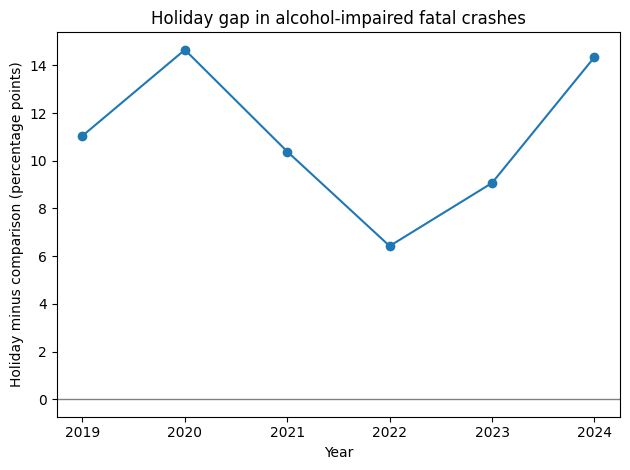

In [ ]:
plt.plot(
    yearly_table.index,
    yearly_table["Gap (percentage points)"],
    marker="o"
)

plt.axhline(0, color="gray", linewidth=1)
plt.xticks(yearly_table.index)
plt.title("Holiday gap in alcohol-impaired fatal crashes")
plt.xlabel("Year")
plt.ylabel("Holiday minus comparison (percentage points)")
plt.tight_layout()
plt.show()

We compared six holiday dates with nearby dates that fell on the same weekdays. In every year from 2019 to 2024, a higher share of fatal crashes on the holiday dates involved a driver with a BAC of 0.08 or higher. The gap fell from 14.65 percentage points in 2020 to 6.42 in 2022, then rose to 14.34 in 2024.

In [23]:
study_data["TIME_OF_DAY"] = pd.cut(
    study_data["HOUR"],
    bins=[0, 6, 12, 18, 24],
    labels=["Overnight", "Morning", "Afternoon", "Evening"],
    right=False
)

study_data["TIME_OF_DAY"] = study_data["TIME_OF_DAY"].cat.add_categories(["Unknown"])
study_data["TIME_OF_DAY"] = study_data["TIME_OF_DAY"].fillna("Unknown")

time_by_group = pd.crosstab(
    study_data["TIME_OF_DAY"],
    study_data["HOLIDAY_DAY"],
    normalize="columns"
) * 100

time_by_group = time_by_group.rename(columns={0: "Comparison %", 1: "Holiday %"})
time_by_group.round(2)

HOLIDAY_DAY,Comparison %,Holiday %
TIME_OF_DAY,,
Overnight,18.73,26.86
Morning,19.47,13.43
Afternoon,28.81,24.98
Evening,32.31,33.98
Unknown,0.67,0.74


In [24]:
rates_by_time = study_data.groupby("TIME_OF_DAY", observed=True)[outcome_columns].mean()
percent_by_time = rates_by_time.mean(axis=1) * 100

percent_by_time.round(2)

TIME_OF_DAY
Overnight    51.15
Morning      14.36
Afternoon    19.50
Evening      37.80
Unknown      59.22
dtype: float64